In [3]:

# 定义一个字典，保存分类号和中文名的映射关系
classification_names = {
    0: '上身衣服',
    1: '鞋',
    2: '包',
    3: '下身衣服',
    4: '手表'
}

## 创建数据集

In [10]:
import pandas as pd
from common.utils import sorted_alphanumeric
from PIL import Image
import os
import torch
from torch.utils.data import Dataset,DataLoader,random_split

# 自定义数据集及标签
class ImageLabelDataset(Dataset):  # 定义一个名为ImageDataset的类，继承自PyTorch的Dataset类
    def __init__(self, main_dir, transform=None):  # 定义类的构造函数，接受两个参数：main_dir（主目录路径）和transform（图像预处理操作，默认为None）
        self.main_dir = main_dir  # 将主目录路径保存为类的属性
        self.transform = transform  # 将图像预处理操作保存为类的属性
        self.all_imgs = sorted_alphanumeric(os.listdir(main_dir))  # 获取所有图像文件名并按字母数字顺序排序
        labels = pd.read_csv("../common/fashion-labels.csv") #读取标签
        self.label_dict = dict(zip(labels['id'], labels['target']))  #将标签保存成字典

    def __len__(self):  # 定义__len__方法，返回数据集中图像的数量
        return len(self.all_imgs)  # 返回主目录下图像文件的数量

    def __getitem__(self, idx):  # 定义__getitem__方法，根据索引idx获取图像
        #1.根据索引号找到文件名，读取图片数据
        img_loc = os.path.join(self.main_dir, self.all_imgs[idx])  # 根据索引idx构建图像的完整路径
        image = Image.open(img_loc).convert("RGB")  # 使用PIL库打开图像并将其转换为RGB格式

        #2.将原始图片转换成符合模型输入要求的张量，这就是重构图像的目标
        if self.transform is not None:  # 如果定义了图像预处理操作
            tensor_image = self.transform(image)  # 对图像进行预处理，并将其转换为张量
        else:
            # 若无变换，抛出异常提示必须提供预处理
            raise ValueError("transform参数不能为None，需指定预处理方法")

        #3.找到图片对应的标签
        label = self.label_dict[idx]

        #将输入和目标返回
        return tensor_image,label  # 返回预处理后的图像张量（将噪声图片作为输入，将原图作为目标）


In [6]:
#定义数据预处理的转换
import torchvision.transforms as T
transform = T.Compose([
    T.Resize((64, 64)),
    T.ToTensor(),
])
dataset =   ImageLabelDataset("../common/dataset", transform)
print(len(dataset))
print(dataset[0])

24853
(tensor([[[1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         ...,
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.]],

        [[1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         ...,
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.]],

        [[1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         ...,
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.],
         [1., 1., 1.,  ..., 1., 1., 1.]]]), 3)


In [11]:
#划分数据集
train_dataset,test_dataset = random_split(dataset,[0.75,0.25])
print(len(train_dataset))
print(len(test_dataset))

18640
6213


In [25]:
# 创建数据加载器
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
print(len(train_loader))

582


In [14]:
for x, y in train_loader:
     print(x.shape, y.shape)
     print()
     break

torch.Size([32, 3, 64, 64]) torch.Size([32])



## 定义模型

In [15]:
from torch import nn,optim
model = nn.Sequential(
    #第一层卷积-池化
    nn.Conv2d(3,8,kernel_size=3,padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2,stride=2),
    #第二层卷积-池化
    nn.Conv2d(8,16,kernel_size=3,padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2,stride=2),

    nn.Flatten(),
    #全连接层
    nn.Linear(4096,5)
)
print(model)

Sequential(
  (0): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=4096, out_features=5, bias=True)
)


In [18]:
data_iter = iter(train_loader)
input, target = next(data_iter)
print(input.shape, target.shape)

torch.Size([32, 3, 64, 64]) torch.Size([32])


In [19]:
# 前向传播测试
output = model(input)
print(output.shape)

torch.Size([32, 5])


# 模型训练

In [20]:
#定义设备
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

Sequential(
  (0): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=4096, out_features=5, bias=True)
)

In [21]:
# 超参数设置
lr = 1e-3
epochs = 5

In [22]:
#定义损失函数和优化器
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

In [23]:
#模型训练
for epoch in range(epochs):
    model.train()
    train_loss = 0
    for input, target in train_loader:
        input, target = input.to(device), target.to(device)
        #前向传播
        output = model(input)
        #计算损失
        loss = loss_fn(output, target)
        #反向传播
        loss.backward()
        #更新参数
        optimizer.step()
        #梯度清零
        optimizer.zero_grad()
        #累加损失
        train_loss += loss.item()
    #本epoch的平均损失
    this_loss = train_loss / len(train_loader)
    print(f"Epoch:{epoch+1} Train Loss:{this_loss:.6f}")



Epoch:1 Train Loss:0.223271
Epoch:2 Train Loss:0.079381
Epoch:3 Train Loss:0.060140
Epoch:4 Train Loss:0.051923
Epoch:5 Train Loss:0.042654


## 模型测试

In [39]:
import matplotlib.pyplot as plt
#1.获取一批测试数据
test_iter = iter(test_loader)
images, labels = next(test_iter)
print(images.shape, labels.shape)

torch.Size([32, 3, 64, 64]) torch.Size([32])


In [40]:
#2.前向传播
with torch.no_grad():
    images = images.to(device)
    output = model(images)
print(output.shape)

torch.Size([32, 5])


In [41]:
#3.将输出转换为分类预测标签
pred_labels = output.argmax(dim=1).cpu().numpy() #取概率最大的那一个标签
print(pred_labels.shape)

(32,)


In [42]:
#4.将输入图像数据转换，方便画图
images = images.permute(0,2,3,1).cpu().numpy()
print(images.shape)

(32, 64, 64, 3)


label-1:4
pred_label-1:4, 分类名:手表

label-2:0
pred_label-2:0, 分类名:上身衣服

label-3:0
pred_label-3:0, 分类名:上身衣服

label-4:0
pred_label-4:0, 分类名:上身衣服

label-5:1
pred_label-5:1, 分类名:鞋

label-6:2
pred_label-6:2, 分类名:包

label-7:1
pred_label-7:1, 分类名:鞋

label-8:1
pred_label-8:1, 分类名:鞋

label-9:2
pred_label-9:2, 分类名:包

label-10:4
pred_label-10:4, 分类名:手表



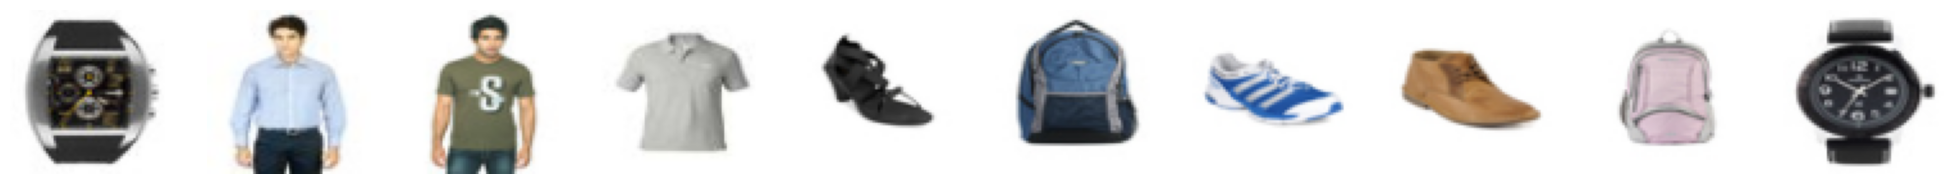

In [43]:
#画图
fig, axes = plt.subplots(1,10,figsize=(25,4), sharex=True,sharey=True)
for i in range(10):
    axes[i].imshow(images[i])
    axes[i].axis('off')
    #打印真实标签和预测标签
    print(f"label-{i+1}:{labels[i]}")
    #转换成中文分类名称
    pred_class = classification_names[pred_labels[i]]
    print(f"pred_label-{i+1}:{pred_labels[i]}, 分类名:{pred_class}")
    print()
plt.show()


In [45]:
# 遍历测试集，计算预测准确率
model.eval()
#记录预测准确个数
test_correct_num = 0
with torch.no_grad():
    for input, target in test_loader:
        input = input.to(device)
        # 前向传播
        output = model(input)
        #预测分裂
        pred = output.argmax(dim=1).cpu()
        #累积预测准确的个数
        test_correct_num += pred.eq(target).sum()
#计算准确率
test_accuracy = test_correct_num / len(test_dataset)
print(test_accuracy)




tensor(0.9868)
